# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the hotels dataset from GitHub
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv'
df = pd.read_csv(url)

# Display the first few rows
print("--- First Few Rows ---")
display(df.head())

# Show summary statistics
print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

--- First Few Rows ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Summary Statistics ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. In the intial preview I scanned for outliers and found that lead time had a very high maximum of 737, meaning that the room was booked over 2 years in advance, which is odd considering that the average lead time was closer to 80 days. Additionally the number of adults in a party also hovered at an average of 1.8, while the maximum was 55. Days in waiting lsit was also odd since the max was 122 while the average was just over 1.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
from sklearn.preprocessing import StandardScaler

# 2.1 Choose numeric features related to customer behavior
features = ['lead_time', 'adults', 'days_in_waiting_list', 'total_of_special_requests']

# Keep only relevant columns for preparation first
df_prep = df[features].copy()

# 2.2 Basic data preparation & Outlier removal
# Let's inspect or filter unreasonable values based on our EDA reflections:
# e.g., adults should be between 1 and 10, days in waiting list should not be negative, etc.
df_prep = df_prep[(df_prep['adults'] > 0) & (df_prep['adults'] < 10)]
df_prep = df_prep[df_prep['lead_time'] >= 0]
df_prep = df_prep[df_prep['days_in_waiting_list'] >= 0]

# Remove duplicate rows
df_prep = df_prep.drop_duplicates()

# 2.3 Drop missing values
df_prep = df_prep.dropna()

# 2.4 Standardize features using StandardScaler
# Large values (over 100) exist in lead_time and days_in_waiting_list, so we'll scale them
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_prep)

# Create a new DataFrame with scaled data
df_scaled = pd.DataFrame(scaled_features, columns=features)

print("--- Data Preparation Complete ---")
print(f"Original dataset shape: {df.shape}")
print(f"Cleaned and scaled dataset shape: {df_scaled.shape}")
print("\nFirst 5 rows of scaled data:")
display(df_scaled.head())

print("\nSummary Statistics of Scaled Data (Mean should be close to 0, Std to 1):")
display(df_scaled.describe())

--- Data Preparation Complete ---
Original dataset shape: (9404, 32)
Cleaned and scaled dataset shape: (1425, 4)

First 5 rows of scaled data:


,lead_time,adults,days_in_waiting_list,total_of_special_requests
0,2.399541,0.101542,-0.070311,-1.026140
1,6.626743,0.101542,-0.070311,-1.026140
2,-1.185554,-1.471258,-0.070311,-1.026140
3,-1.121343,-1.471258,-0.070311,-1.026140
4,-1.110642,0.101542,-0.070311,-0.112805



Summary Statistics of Scaled Data (Mean should be close to 0, Std to 1):


,lead_time,adults,days_in_waiting_list,total_of_special_requests
count,1.425000e+03,1.425000e+03,1.425000e+03,1.425000e+03
mean,3.989012e-17,-1.595605e-16,-2.493132e-17,8.476650e-17
std,1.000351e+00,1.000351e+00,1.000351e+00,1.000351e+00
min,-1.260467e+00,-1.471258e+00,-7.031129e-02,-1.026140e+00
25%,-8.002901e-01,1.015422e-01,-7.031129e-02,-1.026140e+00
50%,-2.330960e-01,1.015422e-01,-7.031129e-02,-1.128049e-01
75%,6.016426e-01,1.015422e-01,-7.031129e-02,8.005302e-01
max,6.626743e+00,6.392741e+00,1.876423e+01,3.540535e+00


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected the numeric variables with the highest outliers since it seemed like standardizing those values would make the overall dataset easier to work with. This included lead time, adults, and wait time. Gemini then recomended that total number of special requests also be standardized.

2. As expected the standardization made the values comparable to one another with higher values in wait list days overall.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

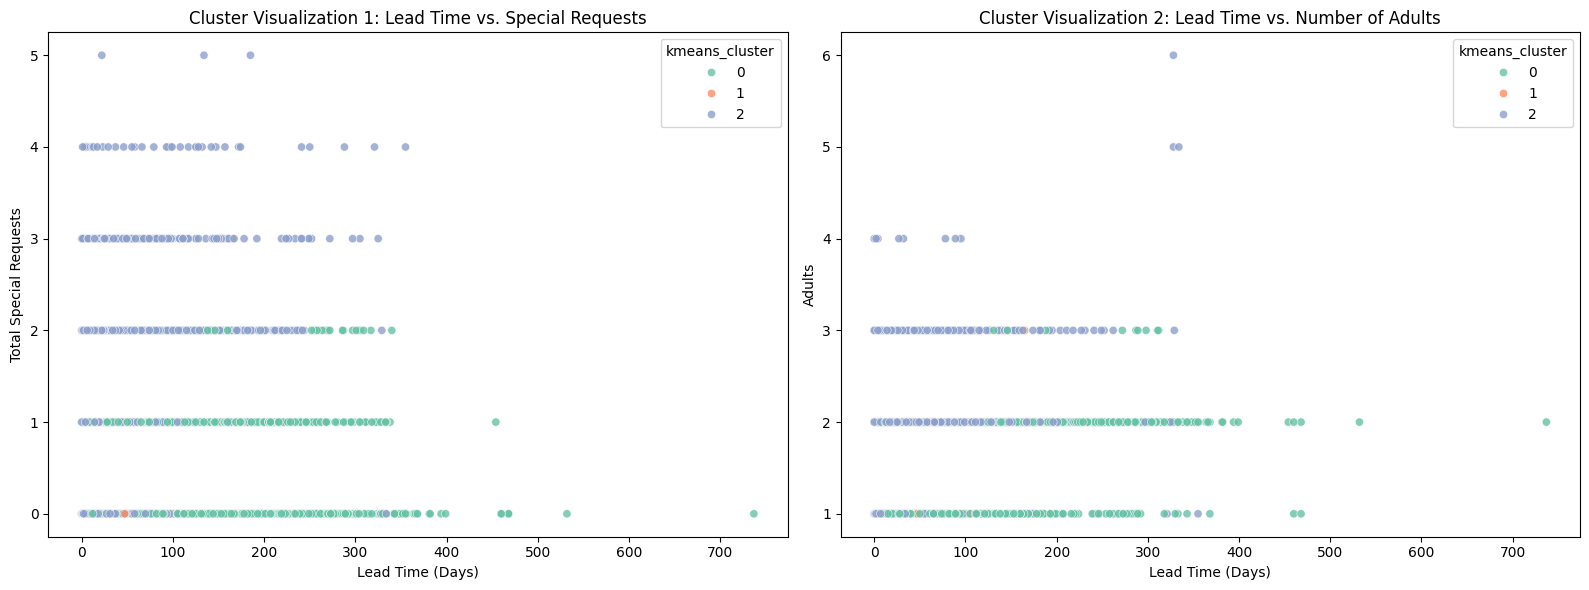


--- K-Means Cluster Averages (Unscaled Profile Summary) ---


,lead_time,adults,days_in_waiting_list,total_of_special_requests
kmeans_cluster,,,,
0,151.608579,1.659517,0.001340,0.447721
1,107.250000,1.750000,80.000000,0.000000
2,80.298063,2.244411,0.011923,1.888227


In [3]:
from sklearn.cluster import KMeans

# 3.1 Fit KMeans and predict clusters (using k=3)
k = 3
k_means_model = KMeans(n_clusters=k, random_state=42, n_init=10)

# Predict clusters using scaled features
df_scaled['kmeans_cluster'] = k_means_model.fit_predict(df_scaled[features])

# Map the assigned clusters back to our original (unscaled) DataFrame
df_prep['kmeans_cluster'] = df_scaled['kmeans_cluster'].values

# 3.2 Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Lead Time vs. Total Special Requests
sns.scatterplot(
    data=df_prep,
    x='lead_time',
    y='total_of_special_requests',
    hue='kmeans_cluster',
    palette='Set2',
    alpha=0.8,
    ax=axes[0]
)
axes[0].set_title('Cluster Visualization 1: Lead Time vs. Special Requests')
axes[0].set_xlabel('Lead Time (Days)')
axes[0].set_ylabel('Total Special Requests')

# Plot 2: Lead Time vs. Adults
sns.scatterplot(
    data=df_prep,
    x='lead_time',
    y='adults',
    hue='kmeans_cluster',
    palette='Set2',
    alpha=0.8,
    ax=axes[1]
)
axes[1].set_title('Cluster Visualization 2: Lead Time vs. Number of Adults')
axes[1].set_xlabel('Lead Time (Days)')
axes[1].set_ylabel('Adults')

plt.tight_layout()
plt.show()

# 3.3 Create a summary table grouped by cluster using the original unscaled values
summary_table = df_prep.groupby('kmeans_cluster')[features].mean()
print("\n--- K-Means Cluster Averages (Unscaled Profile Summary) ---")
display(summary_table)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I selected 3 for both, since K means is intended to be easy to interpret (ie read at a glance) and the data itself is not particularly complex, it made sense to break it into 3 categories.

2. The most recognizable would be found in the lead time vs the number of special requests since most of the parties asking for special requests booked further in advance which would imply that the high maintence clients would be booking bigger events further in advance.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

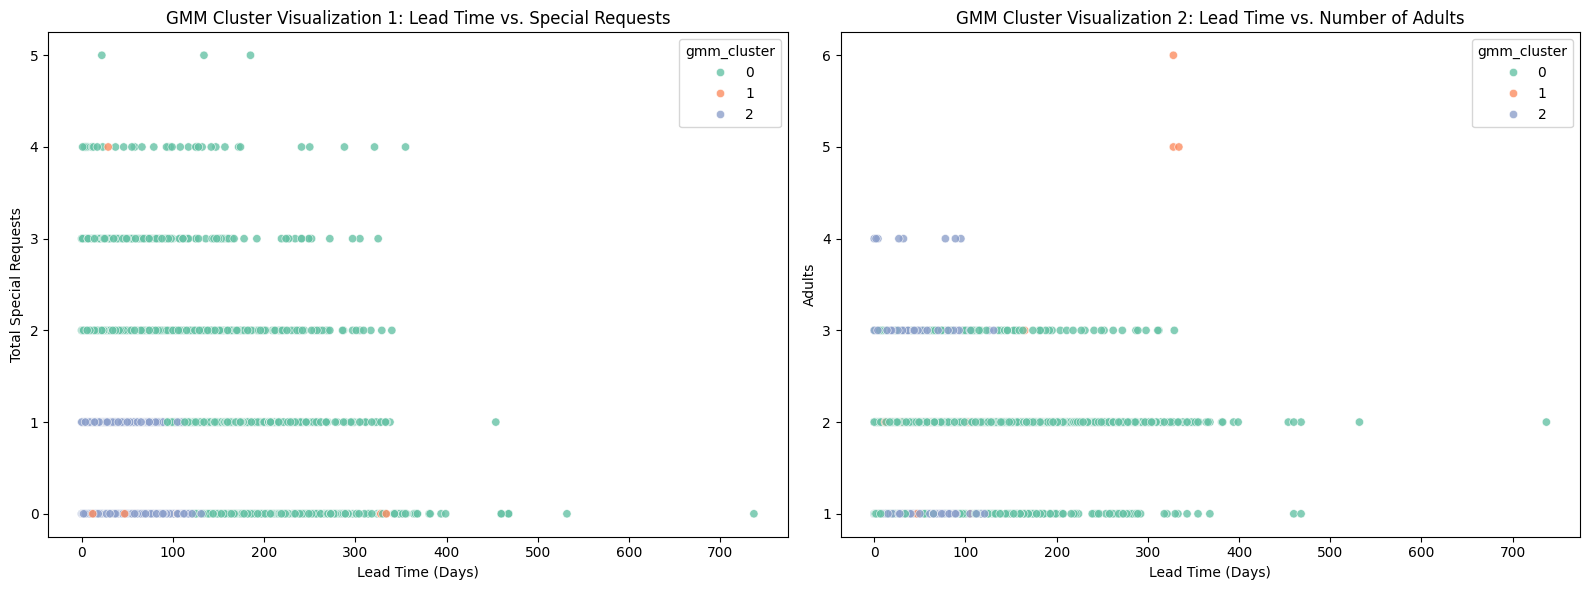


--- GMM Cluster Averages (Unscaled Profile Summary) ---


,lead_time,adults,days_in_waiting_list,total_of_special_requests
gmm_cluster,,,,
0,151.313417,1.918239,0.000000,1.459119
1,145.307692,2.615385,49.923077,0.307692
2,47.152838,1.951965,0.000000,0.447598


In [4]:
from sklearn.mixture import GaussianMixture

# 4.1 Fit GMM with same number of clusters (k=3)
gmm = GaussianMixture(n_components=3, random_state=42)

# Fit and predict (soft clustering probability assignments)
df_scaled['gmm_cluster'] = gmm.fit_predict(df_scaled[features])
df_prep['gmm_cluster'] = df_scaled['gmm_cluster'].values

# 4.2 Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Lead Time vs. Total Special Requests
sns.scatterplot(
    data=df_prep,
    x='lead_time',
    y='total_of_special_requests',
    hue='gmm_cluster',
    palette='Set2',
    alpha=0.8,
    ax=axes[0]
)
axes[0].set_title('GMM Cluster Visualization 1: Lead Time vs. Special Requests')
axes[0].set_xlabel('Lead Time (Days)')
axes[0].set_ylabel('Total Special Requests')

# Plot 2: Lead Time vs. Adults
sns.scatterplot(
    data=df_prep,
    x='lead_time',
    y='adults',
    hue='gmm_cluster',
    palette='Set2',
    alpha=0.8,
    ax=axes[1]
)
axes[1].set_title('GMM Cluster Visualization 2: Lead Time vs. Number of Adults')
axes[1].set_xlabel('Lead Time (Days)')
axes[1].set_ylabel('Adults')

plt.tight_layout()
plt.show()

# 4.3 Create a summary table grouped by GMM cluster using original unscaled values
gmm_summary_table = df_prep.groupby('gmm_cluster')[features].mean()
print("\n--- GMM Cluster Averages (Unscaled Profile Summary) ---")
display(gmm_summary_table)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. The biggest thing I noticed when switching to GMM was the size of the categories, with Kmeans most seemed to be relatively the same size between the green and the blue (0 and 1).

2. The reshuffiling of the categories here meant that far more fell into the category, which means we would be more easily able to ignore the white noise in the sample so to speak. It would likely be more helpful if I was just trying to quickly see which guests were likely to need the most attention at a glace rather than a detailed analysis of when why, especially with a training set of this size.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. K-Means Evaluation
k_means_wcss = k_means_model.inertia_
k_means_silhouette = silhouette_score(df_scaled[features], df_scaled['kmeans_cluster'])
k_means_db_index = davies_bouldin_score(df_scaled[features], df_scaled['kmeans_cluster'])

# 2. GMM Evaluation
# WCSS (Inertia) is not mathematically defined for GMM, so we will look at Silhouette and Davies-Bouldin
gmm_silhouette = silhouette_score(df_scaled[features], df_scaled['gmm_cluster'])
gmm_db_index = davies_bouldin_score(df_scaled[features], df_scaled['gmm_cluster'])

# Output metrics
print("=== K-Means Clustering Metrics ===")
print(f"Within-Cluster Sum of Squares (WCSS): {k_means_wcss:.4f}")
print(f"Silhouette Score: {k_means_silhouette:.4f}")
print(f"Davies-Bouldin Index: {k_means_db_index:.4f}")

print("\n=== Gaussian Mixture Model (GMM) Metrics ===")
print(f"Silhouette Score: {gmm_silhouette:.4f}")
print(f"Davies-Bouldin Index: {gmm_db_index:.4f}")

=== K-Means Clustering Metrics ===
Within-Cluster Sum of Squares (WCSS): 3361.3434
Silhouette Score: 0.2672
Davies-Bouldin Index: 1.1859

=== Gaussian Mixture Model (GMM) Metrics ===
Silhouette Score: 0.1755
Davies-Bouldin Index: 1.6082


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K means performed better by the metrics becuase it has a higher silhoutte score and a lower davies-bouldin index. This would indicate that it was better at creating the categories.

5.3. I would recommend KMeans for the business analyst in this use case specifically because the outcomes were more clearly outlined with less "grey area". In this case the analyst would be looking for easily identifiable patterns, only digging deeper once baseline trends are established. A GMM analysis would be more appropriate if the variables were highly interactive with one another causing there to be overlap in the categories, in this case someone book a room for a day, 2 weeks in advance, would likely not have high categorical overlap with someone staying for a week booking a year in advance, the categories are more distinct.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [8]:
# 6.1 Display and sort characteristics for KMeans Clusters
kmeans_sorted = df_prep.groupby('kmeans_cluster')[features].mean().sort_values(by='lead_time')
print("=== K-Means Clusters Profiles (Sorted by Lead Time) ===")
display(kmeans_sorted)

# 6.2 Display and sort characteristics for GMM Clusters
gmm_sorted = df_prep.groupby('gmm_cluster')[features].mean().sort_values(by='lead_time')
print("\n=== GMM Clusters Profiles (Sorted by Lead Time) ===")
display(gmm_sorted)

=== K-Means Clusters Profiles (Sorted by Lead Time) ===


,lead_time,adults,days_in_waiting_list,total_of_special_requests
kmeans_cluster,,,,
2,80.298063,2.244411,0.011923,1.888227
1,107.250000,1.750000,80.000000,0.000000
0,151.608579,1.659517,0.001340,0.447721



=== GMM Clusters Profiles (Sorted by Lead Time) ===


,lead_time,adults,days_in_waiting_list,total_of_special_requests
gmm_cluster,,,,
2,47.152838,1.951965,0.000000,0.447598
1,145.307692,2.615385,49.923077,0.307692
0,151.313417,1.918239,0.000000,1.459119


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Interestingly the Kmeans and GMM analysis provide slightly varying responses. KMeans indicates that medium level lead times are likely associated with families since they have a higher average number of adults, and a higher number of special requests. GMM on the other hand identifies that the longest lead time guests also had high number of special requests indicating that these people were planners who would get the most out of their experience.

2. One promo that I could see working is allowing guests to pre-select certain types of special requests if they book early by a certain amount of days to give the hotel service the most amount of lead time possible. For example if an ad campaign was set that if you book 3 months early (upwards of 70 days), then you could select bedding preferences, and one room service order free of charge that would help drive up early reservations and decrease the number of unknown special requests for the hotel staff the day the client checks in.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Understanding the limitations of unsupervised learning. It will provide you with patterns and in this case clusters that ideas can be drawn from but it cannot clearly indicate the influnces that came together to get this outcome.

2. Supervised models can be inhibited by the biases of the analysts. If I am assigned a task and my boss or the client explains the task telling me what they think is happening, I am more inclined to search for that during supervised learning when I can direct how the results are being processed as compared to unsupervised learning when the general ideas I come in with can easily be shifted or disproven.

3. Clustering puts all the data points we have into little boxes to make it easier to read. By increasing the interpretability of data you are also improving the comprehension of the team on the whole, it does an analyst no good to have complex data understanding that cannot be shared.

4. As an entreprenuer I am cosntantly presented with the need to collaborate with a wide range of professionals with different skillsets. Understanding how to present data in a quick and understandable format will make it easier to share findings with my team, and will also allow me to quick assess my business standing at any given time which is crucial in the fashion industry since trends move so quickly.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [9]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 625889 bytes to assignment_09_clustering.html
